In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage

In [2]:
# Load the dataset
customer_data = pd.read_csv('customer_segmentation_data.csv')

In [3]:
# Display the first few rows of the dataset
print(customer_data.head())

   id  age  gender  income  spending_score  membership_years  \
0   1   38  Female   99342              90                 3   
1   2   21  Female   78852              60                 2   
2   3   60  Female  126573              30                 2   
3   4   40   Other   47099              74                 9   
4   5   65  Female  140621              21                 3   

   purchase_frequency preferred_category  last_purchase_amount  
0                  24          Groceries                113.53  
1                  42             Sports                 41.93  
2                  28           Clothing                424.36  
3                   5      Home & Garden                991.93  
4                  25        Electronics                347.08  


# Data Preprocessing

In [4]:
# Handle missing values (if any)
customer_data.fillna(method='ffill', inplace=True)

In [5]:
# Feature scaling
# Define columns
numerical_cols = ['age', 'income', 'spending_score', 'membership_years', 'purchase_frequency', 'last_purchase_amount']
categorical_cols = ['gender', 'preferred_category']

# Separate numerical and categorical data
numerical_data = customer_data[numerical_cols]
categorical_data = customer_data[categorical_cols]

# Scale numerical data
scaler = StandardScaler()
scaled_numerical_data = scaler.fit_transform(numerical_data)

# Encode categorical data
encoder = OneHotEncoder(sparse=False, drop='first')
encoded_categorical_data = encoder.fit_transform(categorical_data)

# Combine scaled numerical data and encoded categorical data
scaled_data = np.hstack((scaled_numerical_data, encoded_categorical_data))

# Convert to DataFrame for better readability
num_feature_names = numerical_cols
cat_feature_names = encoder.get_feature_names_out(categorical_cols)
all_feature_names = num_feature_names + list(cat_feature_names)
scaled_df = pd.DataFrame(scaled_data, columns=all_feature_names)

print(scaled_df.head())

        age    income  spending_score  membership_years  purchase_frequency  \
0 -0.384644  0.316868        1.358468         -0.865010           -0.182348   
1 -1.515362 -0.282016        0.321865         -1.215358            1.082005   
2  1.078639  1.112778       -0.714738         -1.215358            0.098620   
3 -0.251618 -1.210096        0.805613          1.237080           -1.516943   
4  1.411203  1.523374       -1.025718         -0.865010           -0.112106   

   last_purchase_amount  gender_Male  gender_Other  \
0             -1.281540          0.0           0.0   
1             -1.523763          0.0           0.0   
2             -0.230005          0.0           0.0   
3              1.690080          0.0           1.0   
4             -0.491443          0.0           0.0   

   preferred_category_Electronics  preferred_category_Groceries  \
0                             0.0                           1.0   
1                             0.0                           0.0   

C:\Users\hp\anaconda3\lib\site-packages\sklearn\preprocessing\_encoders.py:828: FutureWarning: `sparse` was renamed to `sparse_output` in version 1.2 and will be removed in 1.4. `sparse_output` is ignored unless you leave `sparse` to its default value.
  warnings.warn(


In [6]:
# Dimensionality Reduction using PCA
pca = PCA(n_components=2)
pca_data = pca.fit_transform(scaled_data)

# K-Means Clustering

In [7]:
# Determine the optimal number of clusters using the Elbow Method
sse = []
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(pca_data)
    sse.append(kmeans.inertia_)

C:\Users\hp\anaconda3\lib\site-packages\sklearn\cluster\_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
C:\Users\hp\anaconda3\lib\site-packages\sklearn\cluster\_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
C:\Users\hp\anaconda3\lib\site-packages\sklearn\cluster\_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
C:\Users\hp\anaconda3\lib\site-packages\sklearn\cluster\_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
C:\Users\hp\anaconda3\lib\site-packages\sklearn\cluster\_kmeans.py:8

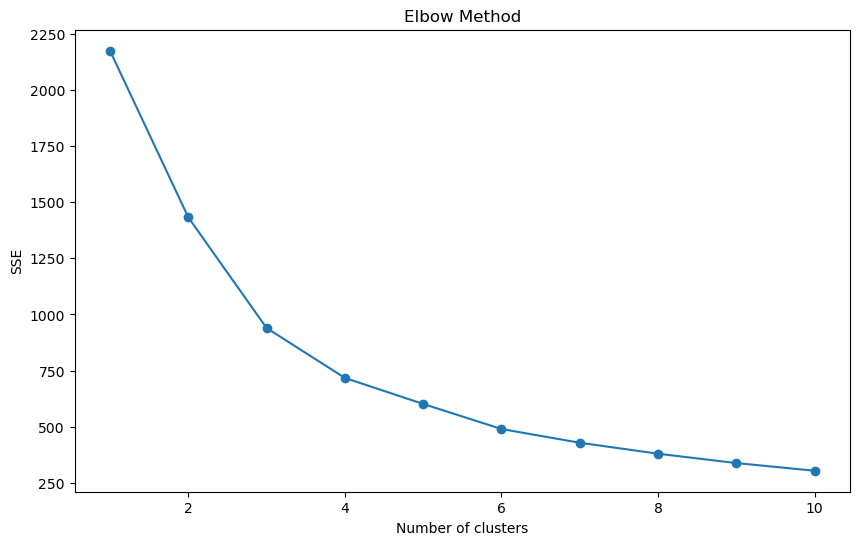

In [8]:
plt.figure(figsize=(10, 6))
plt.plot(range(1, 11), sse, marker='o')
plt.xlabel('Number of clusters')
plt.ylabel('SSE')
plt.title('Elbow Method')
plt.show()

In [9]:
# Choose the optimal number of clusters (e.g., 3 for this example)
optimal_clusters = 3
kmeans = KMeans(n_clusters=optimal_clusters, random_state=42)
clusters = kmeans.fit_predict(pca_data)

C:\Users\hp\anaconda3\lib\site-packages\sklearn\cluster\_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(


In [10]:
# Add the cluster labels to the original data
customer_data['Cluster'] = clusters

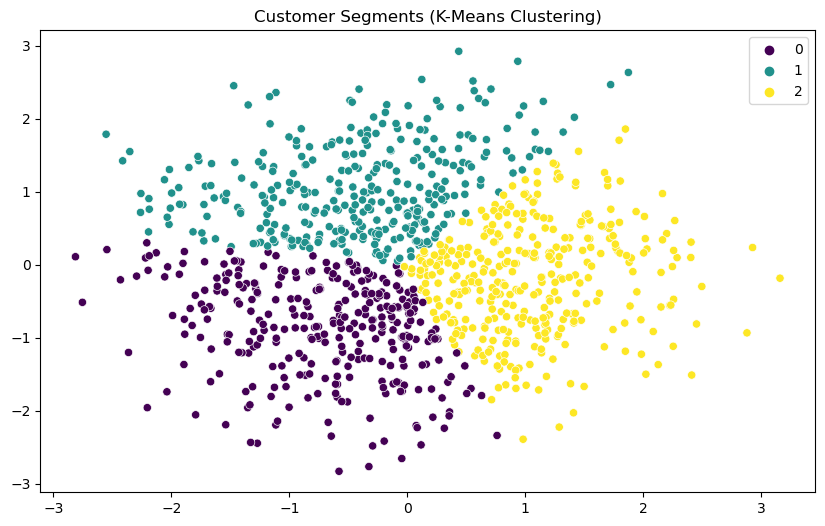

In [11]:
# Visualize the clusters
plt.figure(figsize=(10, 6))
sns.scatterplot(x=pca_data[:, 0], y=pca_data[:, 1], hue=clusters, palette='viridis')
plt.title('Customer Segments (K-Means Clustering)')
plt.show()

# Hierarchical Clustering

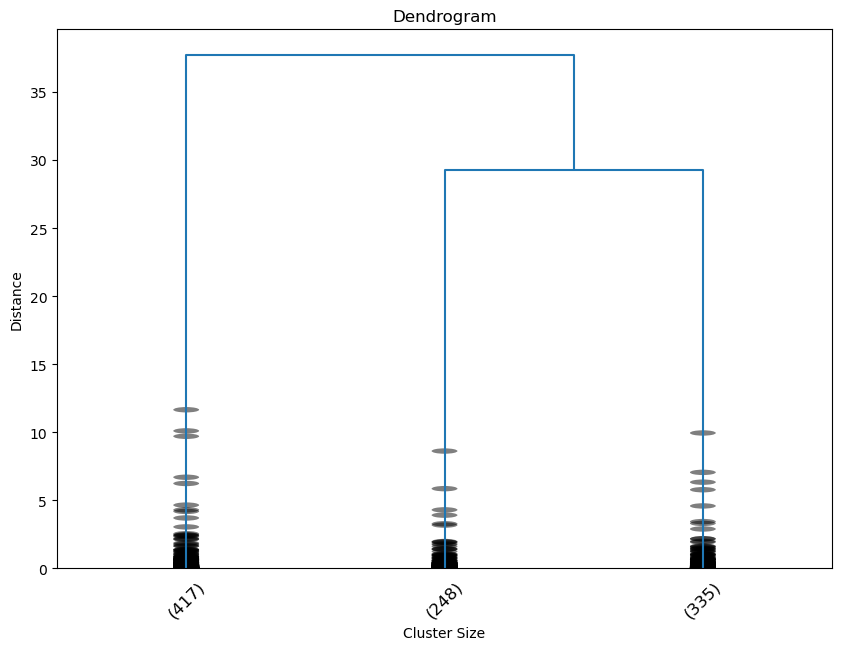

In [12]:
# Perform hierarchical clustering
linked = linkage(pca_data, method='ward')

plt.figure(figsize=(10, 7))
dendrogram(linked, truncate_mode='lastp', p=optimal_clusters, leaf_rotation=45., leaf_font_size=12., show_contracted=True)
plt.title('Dendrogram')
plt.xlabel('Cluster Size')
plt.ylabel('Distance')
plt.show()

In [13]:
# Apply hierarchical clustering with the optimal number of clusters
hierarchical = AgglomerativeClustering(n_clusters=optimal_clusters)
h_clusters = hierarchical.fit_predict(pca_data)

In [14]:
# Add the hierarchical cluster labels to the original data
customer_data['H_Cluster'] = h_clusters

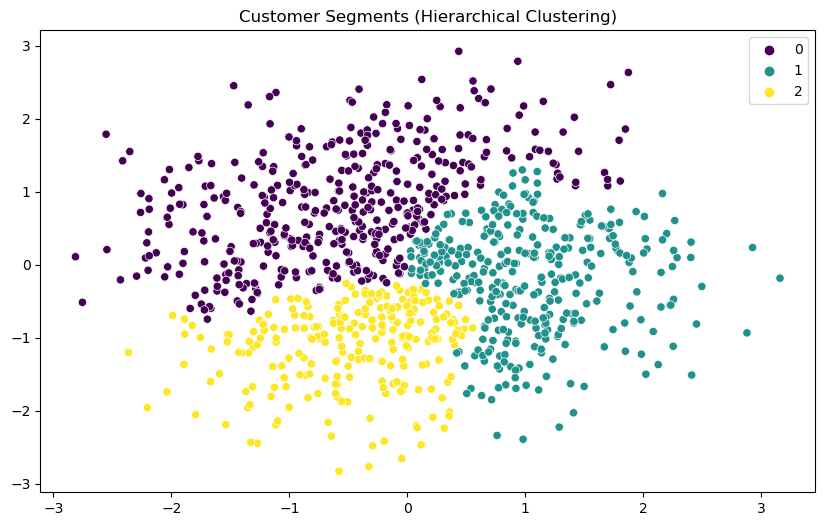

In [15]:
# Visualize the hierarchical clusters
plt.figure(figsize=(10, 6))
sns.scatterplot(x=pca_data[:, 0], y=pca_data[:, 1], hue=h_clusters, palette='viridis')
plt.title('Customer Segments (Hierarchical Clustering)')
plt.show()

In [16]:
# Analyze and Interpret the Clusters
cluster_analysis = customer_data.groupby('Cluster').mean()
print(cluster_analysis)

                 id        age         income  spending_score  \
Cluster                                                         
0        491.322884  35.463950   90101.777429       55.341693   
1        501.843373  53.063253   71171.015060       50.623494   
2        507.610315  42.558739  103523.083095       46.487106   

         membership_years  purchase_frequency  last_purchase_amount  H_Cluster  
Cluster                                                                         
0                7.316614           35.385580            379.037837   1.423197  
1                5.641566           26.825301            728.940542   0.057229  
2                3.616046           18.343840            370.851977   1.025788  


C:\Users\hp\AppData\Local\Temp\ipykernel_9544\680804019.py:2: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  cluster_analysis = customer_data.groupby('Cluster').mean()


In [17]:
# Save the clustered data to a new CSV file
customer_data.to_csv('customer_segments.csv', index=False)